# Gaussian Naive Bayes profitability model

This notebook uses a simple sequence: load data, split data, fill missing values, train GaussianNB, evaluate the test data, and plot the results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, average_precision_score, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
import preprocessing

## Load and inspect the prepared records

The CSV has 150 predictor columns and the binary `profitable` target. Profit is 1 and Loss is 0. The classes are balanced because the source data was undersampled.

In [2]:
df = pd.read_csv(preprocessing.TRAIN_DATA_PATH, low_memory=False)
X = df.drop(columns=["profitable"])
y = df["profitable"]
print("Feature shape:", X.shape)
print("Class balance:\n", y.value_counts())

Feature shape: (439339, 134)
Class balance:
 profitable
1    219670
0    219669
Name: count, dtype: int64


## Define training and test sets using the separated datasets from Datavisualization

The test set is held out until the end. Stratification keeps the Profit/Loss proportions consistent.

In [3]:
test_df = pd.read_csv(preprocessing.TEST_DATA_PATH, low_memory=False)
X_train, y_train = X, y
X_test = test_df.drop(columns=["profitable"])
y_test = test_df["profitable"]
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("class balance per split:", y_train.mean(), y_test.mean())  # all ~0.5

Training rows: 439339
Test rows: 109835
class balance per split: 0.5000011380733329 0.4999954477170301


In [4]:
preprocessor = ColumnTransformer(
    transformers=[("median_imputer", SimpleImputer(strategy="median"), make_column_selector(dtype_include="number"))],
    remainder="passthrough",
)

## Fill missing values and train GaussianNB

In order to fine tune the parameter used in the GaussianNB function, a GridSearchCV was used to compare different values of var_smoothing. 5-fold validation was used to compare the probability ranking of each setting. Based on those results, the following parameter was chosen for the active model.

The active model uses the previously selected value: var_smoothing 1e-12. The imputer addresses values with missing data by replacing them with the median of that column.

The search code can be viewed in the commented cell below. It is currently commented so the other code can be run as simply as possible.

In [5]:
nb_search = GridSearchCV(
    Pipeline([
        ("preprocessor", preprocessor),
        ("model", GaussianNB()),
    ]),
    {"model__var_smoothing": np.logspace(-12, -6, 12)},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=preprocessing.RANDOM_STATE),
    scoring="accuracy",
    n_jobs=-1,
    refit=False,
)
nb_search.fit(X_train, y_train)
print("Best parameters:", nb_search.best_params_)
# Best parameters: {'model__var_smoothing': 1e-12}

/opt/anaconda3/envs/SURE312/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters: {'model__var_smoothing': 1e-12}


After the best parameter is chosen, we use k-fold CV to compare the train and val metrics for each fold.

In [6]:
k = 5
kfold = StratifiedKFold(n_splits=k, shuffle=True, random_state=12)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

def run_cv(model):
    """Run k-fold cross-validation and return a table with one row per fold."""
    results = cross_validate(model, X_train, y_train, cv=kfold, scoring=scoring, return_train_score=True, n_jobs=-1)
    table = pd.DataFrame({"Fold": range(1, k + 1)})
    for metric in scoring:
        table["Train " + metric] = results["train_" + metric]
        table["Val " + metric] = results["test_" + metric]
    return table.set_index("Fold")

def summarize(folds):
    summary = pd.DataFrame({
        "Mean": folds.mean(),
        "Std. deviation": folds.std(ddof=0)
    })
    return summary

def mean_std_table(folds):
    return folds.apply(lambda col: f"{col.mean():.3f} \u00b1 {col.std(ddof=0):.3f}")

nb_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GaussianNB(var_smoothing=nb_search.best_params_["model__var_smoothing"])),
])

nb_folds = run_cv(nb_pipe)
nb_folds

,Train accuracy,Val accuracy,Train precision,Val precision,Train recall,Val recall,Train f1,Val f1,Train roc_auc,Val roc_auc,Train average_precision,Val average_precision
Fold,,,,,,,,,,,,
1,0.620265,0.618678,0.655723,0.653272,0.506419,0.505827,0.571480,0.570171,0.666834,0.665491,0.634537,0.633775
2,0.621425,0.622149,0.652782,0.654703,0.518812,0.516934,0.578137,0.577719,0.667180,0.666866,0.635271,0.635190
3,0.628635,0.628807,0.634866,0.635202,0.605539,0.605158,0.619856,0.619816,0.667451,0.665709,0.637463,0.634973
4,0.619095,0.622115,0.655889,0.658794,0.501087,0.506624,0.568132,0.572774,0.666368,0.668321,0.634196,0.637076
5,0.617992,0.618002,0.658629,0.659205,0.489905,0.488619,0.561874,0.561236,0.667968,0.668002,0.635392,0.634520


In [7]:
summarize(nb_folds)

,Mean,Std. deviation
Train accuracy,0.621483,0.003756
Val accuracy,0.621950,0.003831
Train precision,0.651578,0.008558
Val precision,0.652235,0.008819
Train recall,0.524352,0.041645
Val recall,0.524632,0.041276
Train f1,0.579896,0.020659
Val f1,0.580343,0.020449
Train roc_auc,0.667160,0.000542
Val roc_auc,0.666878,0.001152


In [8]:
comparison_cv = pd.DataFrame({
    "Gaussian NB": mean_std_table(nb_folds),
})
comparison_cv

,Gaussian NB
Train accuracy,0.621 ± 0.004
Val accuracy,0.622 ± 0.004
Train precision,0.652 ± 0.009
Val precision,0.652 ± 0.009
Train recall,0.524 ± 0.042
Val recall,0.525 ± 0.041
Train f1,0.580 ± 0.021
Val f1,0.580 ± 0.020
Train roc_auc,0.667 ± 0.001
Val roc_auc,0.667 ± 0.001


## Evaluate the held-out test data

After having used cross validation to select the smoothing parameter, the model can be tested.

The fitted model is evaluated once on the held-out test data. The test data is transformed with the medians calculated from the training data and is not used during parameter selection.

In [9]:
nb_pipe.fit(X_train, y_train)

test_probability = nb_pipe.predict_proba(X_test)[:, 1]
test_prediction = nb_pipe.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, test_prediction), 4))
print("Precision:", round(precision_score(y_test, test_prediction, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_prediction, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, test_prediction, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probability), 4))
print("Average precision:", round(average_precision_score(y_test, test_probability), 4))

Accuracy: 0.6251
Precision: 0.658
Recall: 0.5211
F1-score: 0.5816
ROC-AUC: 0.6702
Average precision: 0.6388


## Plot the test results

The confusion matrix shows mistakes. ROC-AUC shows ranking quality. The precision-recall curve shows how precision and recall change across thresholds.

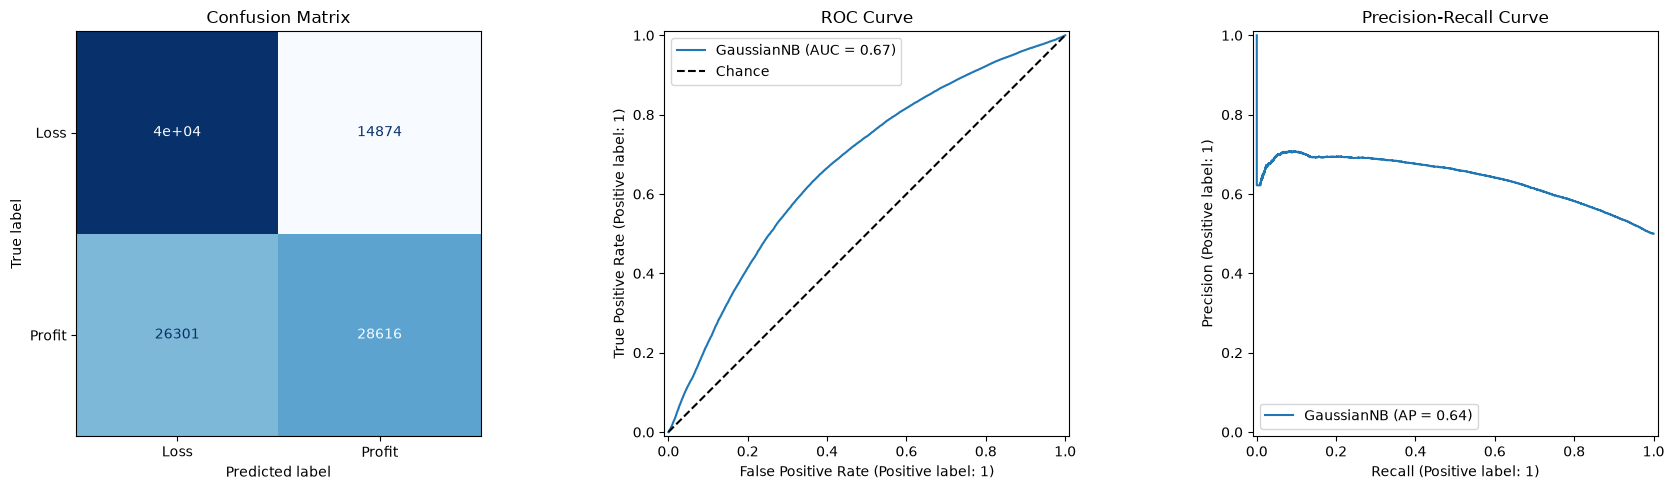

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, display_labels=["Loss", "Profit"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, test_probability, name="GaussianNB", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].legend()
axes[1].set_title("ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, test_probability, name="GaussianNB", ax=axes[2])
axes[2].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

In [11]:
print(confusion_matrix(y_test, test_prediction))

[[40044 14874]
 [26301 28616]]


In [12]:
len(y_test)

109835